# Dataset split and class-balance analysis

This notebook audits the exact data splits used by `training/experiment.py` to help diagnose overfitting.

It checks:
- class counts in the official train and test CSV files;
- the generated train/validation split inside every training partition and cycle;
- missing or underrepresented classes;
- distribution drift between train, validation, and test;
- duplicate videos and participant overlap;
- validation coverage and repeated validation reuse across partition cycles.

> Run all cells from the repository root. Change the configuration below to match an experiment.

In [45]:
!pip install seaborn


[notice] A new release of pip is available: 26.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip


In [46]:
from collections import Counter
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "training").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from training.config import ExperimentConfig
from training.data import load_split_records
from training.experiment import _partition_records
from training.scenario_splits import build_training_validation_split

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 50)

## Configuration

These defaults mirror `ExperimentConfig`. Validation is not a fixed CSV: the training pipeline first partitions the official training set, then creates a stratified validation subset inside each partition.

In [47]:
CONFIG = ExperimentConfig()
DATASET_DIR = PROJECT_ROOT / CONFIG.dataset_dir
SCENARIOS = ["sd", "si"]
TRAIN_PARTITIONS = CONFIG.train_partitions
PARTITION_CYCLES = CONFIG.partition_cycles
VALIDATION_FRACTION = CONFIG.validation_fraction
SEED = CONFIG.seed

print(f"Dataset: {DATASET_DIR}")
print(f"Scenarios: {SCENARIOS}")
print(f"Partitions: {TRAIN_PARTITIONS}, cycles: {PARTITION_CYCLES}")
print(f"Validation fraction: {VALIDATION_FRACTION:.1%}, seed: {SEED}")

Dataset: /app/Dataset
Scenarios: ['sd', 'si']
Partitions: 6, cycles: 3
Validation fraction: 20.0%, seed: 128


In [48]:
def records_to_frame(records):
    return pd.DataFrame(record.to_dict() for record in records)


official = {}
for scenario in SCENARIOS:
    official[(scenario, "train")] = records_to_frame(
        load_split_records(DATASET_DIR, scenario, "train")
    )
    official[(scenario, "test")] = records_to_frame(
        load_split_records(DATASET_DIR, scenario, "test")
    )

dataset_overview = pd.DataFrame([
    {
        "scenario": scenario,
        "split": split,
        "samples": len(frame),
        "classes": frame["gloss"].nunique(),
        "participants": frame["participant_id"].nunique(),
        "unique_videos": frame["video_file"].nunique(),
    }
    for (scenario, split), frame in official.items()
])
dataset_overview

,scenario,split,samples,classes,participants,unique_videos
0,sd,train,50456,2731,52,50456
1,sd,test,32943,2731,52,32943
2,si,train,50458,2731,41,50458
3,si,test,32941,2731,11,32941


## Official train/test class balance

In [49]:
def class_counts(frame, split_name):
    return frame.groupby("gloss").size().rename(split_name)


def imbalance_summary(counts, scenario, split):
    counts = counts[counts > 0]
    return {
        "scenario": scenario,
        "split": split,
        "samples": int(counts.sum()),
        "classes": int(len(counts)),
        "min": int(counts.min()),
        "median": float(counts.median()),
        "mean": float(counts.mean()),
        "max": int(counts.max()),
        "max/min ratio": float(counts.max() / counts.min()),
        "classes <= 2": int((counts <= 2).sum()),
        "classes <= 5": int((counts <= 5).sum()),
    }


official_tables = {}
imbalance_rows = []
for scenario in SCENARIOS:
    train_counts = class_counts(official[(scenario, "train")], "official_train")
    test_counts = class_counts(official[(scenario, "test")], "official_test")
    table = pd.concat([train_counts, test_counts], axis=1).fillna(0).astype(int)
    table["total"] = table.sum(axis=1)
    table["test/train ratio"] = np.where(
        table["official_train"] > 0,
        table["official_test"] / table["official_train"],
        np.nan,
    )
    official_tables[scenario] = table.sort_values("official_train")
    imbalance_rows.append(imbalance_summary(train_counts, scenario, "official_train"))
    imbalance_rows.append(imbalance_summary(test_counts, scenario, "official_test"))

pd.DataFrame(imbalance_rows).round(2)

,scenario,split,samples,classes,min,median,mean,max,max/min ratio,classes <= 2,classes <= 5
0,sd,official_train,50456,2731,9,19.0,18.48,29,3.22,0,0
1,sd,official_test,32943,2731,3,12.0,12.06,22,7.33,0,23
2,si,official_train,50458,2731,13,18.0,18.48,28,2.15,0,0
3,si,official_test,32941,2731,7,12.0,12.06,20,2.86,0,0


In [50]:
for scenario, table in official_tables.items():
    missing_train = table.index[table["official_train"] == 0].tolist()
    missing_test = table.index[table["official_test"] == 0].tolist()
    print(f"{scenario.upper()}: {len(table)} classes in the union")
    print(f"  absent from train: {len(missing_train)}")
    print(f"  absent from test:  {len(missing_test)}")
    if missing_train:
        print("  train-missing labels:", missing_train)
    if missing_test:
        print("  test-missing labels:", missing_test[:30], "..." if len(missing_test) > 30 else "")

SD: 2731 classes in the union
  absent from train: 0
  absent from test:  0
SI: 2731 classes in the union
  absent from train: 0
  absent from test:  0


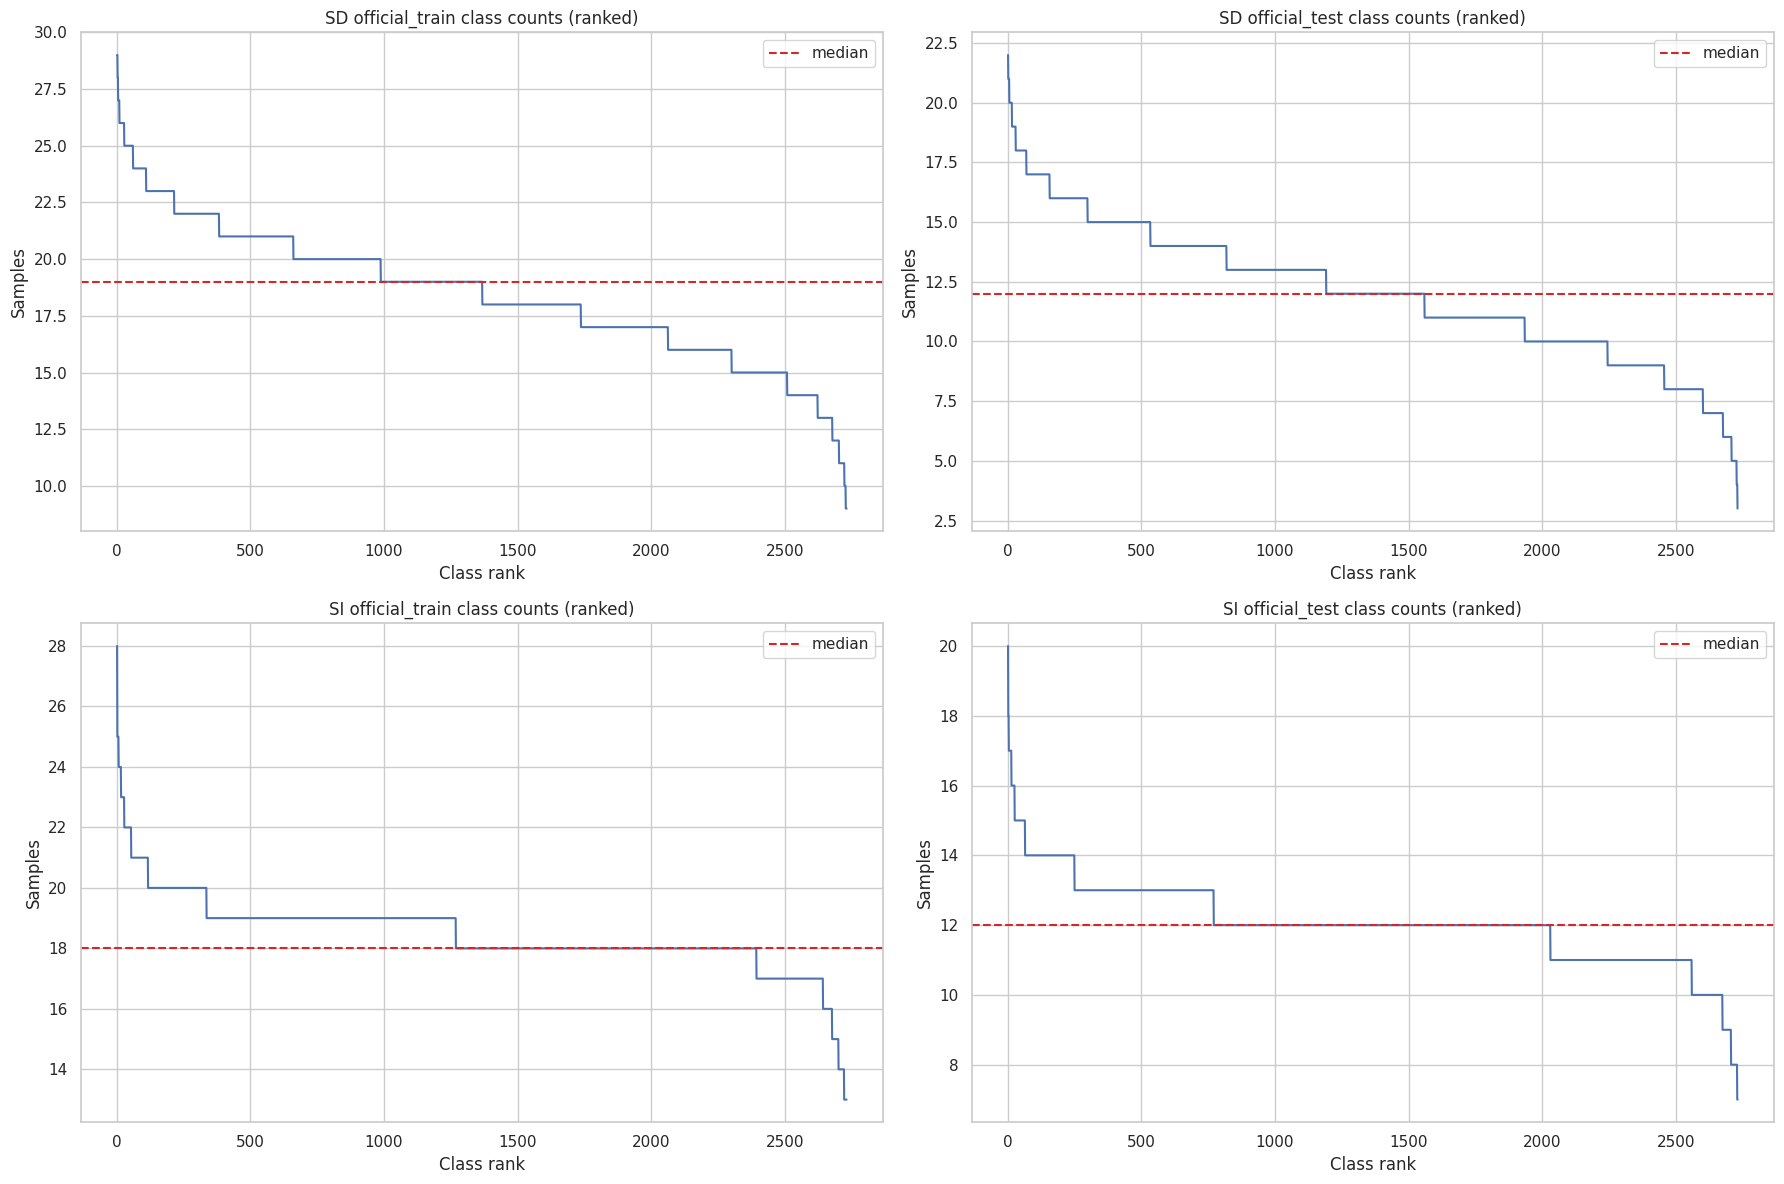

In [51]:
fig, axes = plt.subplots(len(SCENARIOS), 2, figsize=(18, 6 * len(SCENARIOS)))
axes = np.atleast_2d(axes)
for row, scenario in enumerate(SCENARIOS):
    table = official_tables[scenario]
    for col, split in enumerate(["official_train", "official_test"]):
        values = table[split].sort_values(ascending=False).reset_index(drop=True)
        axes[row, col].plot(values.index + 1, values.values, linewidth=1.5)
        axes[row, col].axhline(values.median(), color="tab:red", linestyle="--", label="median")
        axes[row, col].set(title=f"{scenario.upper()} {split} class counts (ranked)", xlabel="Class rank", ylabel="Samples")
        axes[row, col].legend()
plt.tight_layout()
plt.show()

The tables below expose the smallest and largest classes. Very small classes are especially important because the pipeline keeps singleton classes in training and cannot place them in validation.

In [52]:
for scenario, table in official_tables.items():
    print(f"\n{scenario.upper()} - 20 smallest training classes")
    display(table.sort_values("official_train").head(20))
    print(f"{scenario.upper()} - 20 largest training classes")
    display(table.sort_values("official_train", ascending=False).head(20))


SD - 20 smallest training classes


,official_train,official_test,total,test/train ratio
gloss,,,,
ROCKINGCHAIR2,9,14,23,1.555556
RIVER2,9,14,23,1.555556
MOVIE2,9,15,24,1.666667
BELIEVE2,9,14,23,1.555556
CANCEL2,10,13,23,1.300000
LETKNOW,10,19,29,1.900000
GUESS2,10,12,22,1.200000
TYPE2,10,12,22,1.200000
SPECIAL2,10,13,23,1.300000


SD - 20 largest training classes


,official_train,official_test,total,test/train ratio
gloss,,,,
MECHANIC1,29,10,39,0.344828
APPEAR,29,3,32,0.103448
BASKETBALL1,28,16,44,0.571429
WHATFOR1,28,15,43,0.535714
BELT1,27,13,40,0.481481
NOON1,27,11,38,0.407407
TYPE1,27,11,38,0.407407
FRAUD,27,4,31,0.148148
GAY,27,4,31,0.148148



SI - 20 smallest training classes


,official_train,official_test,total,test/train ratio
gloss,,,,
LETTUCE2,13,8,21,0.615385
NIGHT2,13,10,23,0.769231
CLOUD2,13,9,22,0.692308
BREAKFAST2,13,10,23,0.769231
DEMAND2,13,9,22,0.692308
DEAF2,13,10,23,0.769231
BEE2,13,8,21,0.615385
BELIEVE2,13,10,23,0.769231
MECHANIC2,13,9,22,0.692308


SI - 20 largest training classes


,official_train,official_test,total,test/train ratio
gloss,,,,
DOG1,28,17,45,0.607143
BITE1,25,14,39,0.560000
HURDLE/TRIP1,25,13,38,0.520000
BEE1,25,14,39,0.560000
DEMAND1,25,14,39,0.560000
WHATFOR1,25,18,43,0.720000
BREAKFAST1,24,15,39,0.625000
DEAF1,24,15,39,0.625000
ROCKINGCHAIR1,24,15,39,0.625000


## Reconstruct the actual partition-level train/validation splits

This calls the private helpers used by the current training implementation. Each row below is one class inside one partition and cycle.

In [53]:
def reconstruct_training_splits(scenario):
    records = load_split_records(DATASET_DIR, scenario, "train")
    rows = []
    membership_rows = []

    split_plan = build_training_validation_split(
        records, scenario, VALIDATION_FRACTION, SEED
    )
    validation_counts = Counter(record.gloss for record in split_plan.validation_records)
    for cycle in range(PARTITION_CYCLES):
        partitions = _partition_records(
            split_plan.training_records, TRAIN_PARTITIONS, SEED + cycle
        )
        for partition_index, partition in enumerate(partitions, start=1):
            partition_counts = Counter(record.gloss for record in partition)
            for gloss in sorted(partition_counts):
                rows.append({
                    "scenario": scenario,
                    "cycle": cycle + 1,
                    "partition": partition_index,
                    "gloss": gloss,
                    "partition_count": partition_counts[gloss],
                    "train_count": partition_counts[gloss],
                    "validation_count": validation_counts[gloss] if partition_index == 1 else 0,
                })
            membership_rows.extend({
                "scenario": scenario,
                "cycle": cycle + 1,
                "partition": partition_index,
                "split": "train",
                "video_file": record.video_file,
                "participant_id": record.participant_id,
                "gloss": record.gloss,
            } for record in partition)
        membership_rows.extend({
                    "scenario": scenario,
                    "cycle": cycle + 1,
                    "partition": 0,
                    "split": "validation",
                    "video_file": record.video_file,
                    "participant_id": record.participant_id,
                    "gloss": record.gloss,
                } for record in split_plan.validation_records)

    return pd.DataFrame(rows), pd.DataFrame(membership_rows)


partition_class_frames = []
membership_frames = []
for scenario in SCENARIOS:
    class_frame, membership_frame = reconstruct_training_splits(scenario)
    partition_class_frames.append(class_frame)
    membership_frames.append(membership_frame)

partition_classes = pd.concat(partition_class_frames, ignore_index=True)
memberships = pd.concat(membership_frames, ignore_index=True)
partition_classes.head()

,scenario,cycle,partition,gloss,partition_count,train_count,validation_count
0,sd,1,1,1DOLLAR,4,4,4
1,sd,1,1,5DOLLARS,2,2,3
2,sd,1,1,9OCLOCK,2,2,4
3,sd,1,1,A-LINEBOB,4,4,3
4,sd,1,1,ABBREVIATE,5,5,3


In [54]:
partition_summary = (
    partition_classes.groupby(["scenario", "cycle", "partition"])
    .agg(
        partition_samples=("partition_count", "sum"),
        train_samples=("train_count", "sum"),
        validation_samples=("validation_count", "sum"),
        partition_classes=("gloss", "nunique"),
        validation_classes=("validation_count", lambda values: int((values > 0).sum())),
        singleton_classes=("partition_count", lambda values: int((values == 1).sum())),
    )
    .reset_index()
)
partition_summary["validation_fraction_actual"] = (
    partition_summary["validation_samples"] / partition_summary["partition_samples"]
)
partition_summary["classes_missing_from_validation"] = (
    partition_summary["partition_classes"] - partition_summary["validation_classes"]
)
partition_summary.round(3)

,scenario,cycle,partition,partition_samples,train_samples,validation_samples,partition_classes,validation_classes,singleton_classes,validation_fraction_actual,classes_missing_from_validation
0,sd,1,1,6728,6728,9335,2510,2510,527,1.387,0
1,sd,1,2,6728,6728,0,2521,0,546,0.000,2521
2,sd,1,3,6728,6728,0,2540,0,603,0.000,2540
3,sd,1,4,6728,6728,0,2532,0,592,0.000,2532
4,sd,1,5,6728,6728,0,2534,0,555,0.000,2534
5,sd,1,6,6723,6723,0,2545,0,561,0.000,2545
6,sd,2,1,6728,6728,9439,2543,2543,571,1.403,0
7,sd,2,2,6728,6728,0,2515,0,542,0.000,2515
8,sd,2,3,6728,6728,0,2520,0,562,0.000,2520
9,sd,2,4,6728,6728,0,2520,0,548,0.000,2520


In [55]:
class_risk = (
    partition_classes.groupby(["scenario", "gloss"])
    .agg(
        appearances=("partition", "size"),
        total_partition_samples=("partition_count", "sum"),
        total_train_samples=("train_count", "sum"),
        total_validation_samples=("validation_count", "sum"),
        validation_appearances=("validation_count", lambda values: int((values > 0).sum())),
        singleton_partition_appearances=("partition_count", lambda values: int((values == 1).sum())),
        min_partition_count=("partition_count", "min"),
        max_partition_count=("partition_count", "max"),
    )
    .reset_index()
)
class_risk["validation_coverage"] = class_risk["validation_appearances"] / class_risk["appearances"]

for scenario in SCENARIOS:
    risky = class_risk[class_risk["scenario"] == scenario].sort_values(
        ["validation_coverage", "total_validation_samples", "total_partition_samples"]
    )
    print(f"\n{scenario.upper()} - classes with weakest validation coverage")
    display(risky.head(30))


SD - classes with weakest validation coverage


,scenario,gloss,appearances,total_partition_samples,total_train_samples,total_validation_samples,validation_appearances,singleton_partition_appearances,min_partition_count,max_partition_count,validation_coverage
2078,sd,SHARP2,14,36,36,0,0,3,1,5,0.000000
968,sd,FULL,14,39,39,0,0,3,1,5,0.000000
1313,sd,KNIGHT2,16,27,27,2,1,7,1,3,0.062500
2465,sd,TOMORROW,16,30,30,2,1,5,1,3,0.062500
91,sd,ASSIGN,16,33,33,3,1,6,1,4,0.062500
525,sd,CORKSCREW2,16,36,36,3,1,7,1,5,0.062500
1199,sd,HURDLE/TRIP2,16,36,36,3,1,4,1,4,0.062500
2636,sd,WEST,16,36,36,3,1,6,1,5,0.062500
1449,sd,MARIONETTE,16,39,39,3,1,4,1,5,0.062500
2348,sd,SWEATER1,16,39,39,3,1,5,1,7,0.062500



SI - classes with weakest validation coverage


,scenario,gloss,appearances,total_partition_samples,total_train_samples,total_validation_samples,validation_appearances,singleton_partition_appearances,min_partition_count,max_partition_count,validation_coverage
3011,si,BREAK,16,45,45,2,1,2,1,5,0.062500
3277,si,CRAWL1,16,45,45,2,1,3,1,6,0.062500
3163,si,CHINA,16,42,42,3,1,3,1,5,0.062500
3272,si,CRACKER1,16,42,42,3,1,4,1,5,0.062500
2949,si,BLEED,16,45,45,3,1,4,1,5,0.062500
3946,si,IMMERSE,16,45,45,3,1,4,1,7,0.062500
4137,si,LONGTIME,16,45,45,3,1,3,1,6,0.062500
2973,si,BOMB,16,48,48,3,1,3,1,6,0.062500
3164,si,CHOCOLATE,16,39,39,4,1,3,1,4,0.062500
3058,si,CALCULATOR,16,42,42,4,1,3,1,6,0.062500


## Aggregate effective train/validation counts

Because each official training sample is revisited in every cycle, these totals describe how often each class contributes to optimization and validation across a complete run. The current implementation repeats the same validation membership in every cycle.

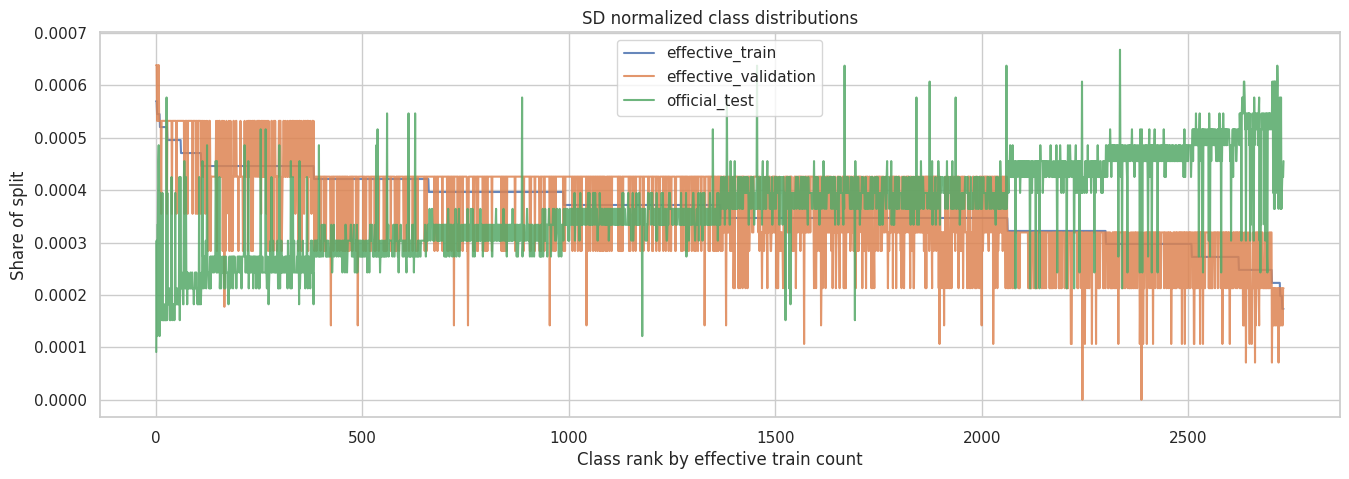

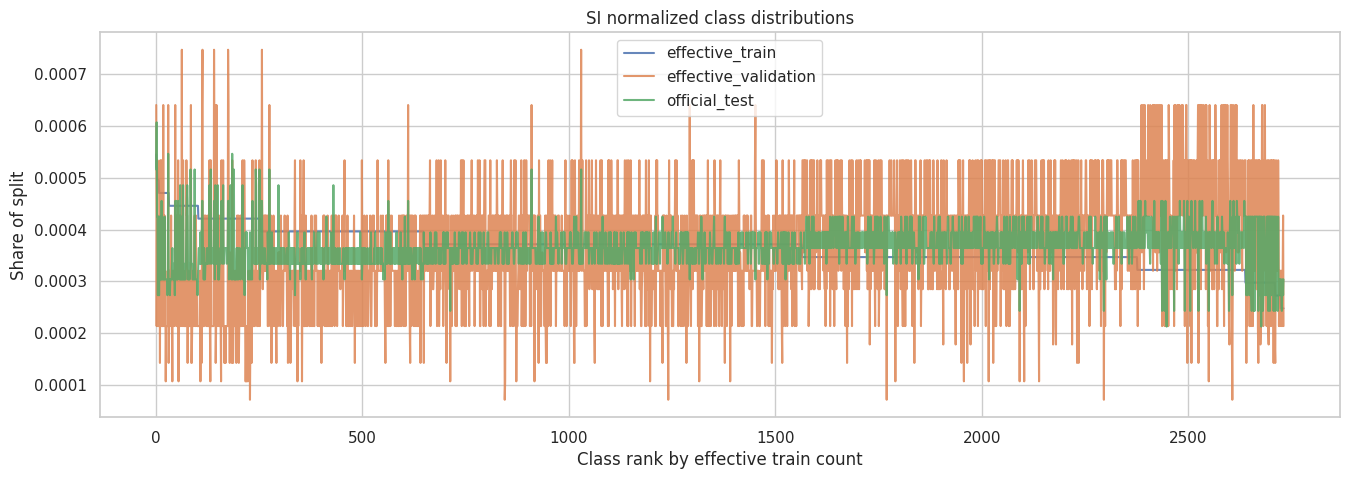

In [56]:
effective_counts = (
    partition_classes.groupby(["scenario", "gloss"])[["train_count", "validation_count"]]
    .sum()
    .reset_index()
)

for scenario in SCENARIOS:
    table = effective_counts.loc[
        effective_counts["scenario"] == scenario,
        ["gloss", "train_count", "validation_count"],
    ].set_index("gloss")
    table = table.rename(columns={"train_count": "effective_train", "validation_count": "effective_validation"})
    table = table.join(official_tables[scenario][["official_test"]], how="outer").fillna(0)
    normalized = table.div(table.sum(axis=0), axis=1)
    plot_data = normalized.sort_values("effective_train", ascending=False).reset_index(drop=True)

    fig, ax = plt.subplots(figsize=(16, 5))
    for column in plot_data.columns:
        ax.plot(plot_data.index + 1, plot_data[column], label=column, alpha=0.85)
    ax.set(title=f"{scenario.upper()} normalized class distributions", xlabel="Class rank by effective train count", ylabel="Share of split")
    ax.legend()
    plt.show()

## Distribution drift metrics

`total_variation` is 0 for identical distributions and approaches 1 as they diverge. Jensen-Shannon divergence is also 0 for identical distributions and remains finite when a class is absent from one split.

In [57]:
def normalized(values):
    values = np.asarray(values, dtype=float)
    return values / values.sum()


def total_variation(p, q):
    return 0.5 * np.abs(p - q).sum()


def js_divergence(p, q):
    midpoint = 0.5 * (p + q)
    def kl(a, b):
        mask = a > 0
        return np.sum(a[mask] * np.log2(a[mask] / b[mask]))
    return 0.5 * kl(p, midpoint) + 0.5 * kl(q, midpoint)


drift_rows = []
for scenario in SCENARIOS:
    effective = effective_counts.loc[
        effective_counts["scenario"] == scenario,
        ["gloss", "train_count", "validation_count"],
    ].set_index("gloss")
    combined = effective.join(official_tables[scenario][["official_test"]], how="outer").fillna(0)
    distributions = {column: normalized(combined[column]) for column in combined.columns}
    for left, right in [("train_count", "validation_count"), ("train_count", "official_test"), ("validation_count", "official_test")]:
        drift_rows.append({
            "scenario": scenario,
            "comparison": f"{left} vs {right}",
            "total_variation": total_variation(distributions[left], distributions[right]),
            "jensen_shannon": js_divergence(distributions[left], distributions[right]),
        })

pd.DataFrame(drift_rows).round(4)

,scenario,comparison,total_variation,jensen_shannon
0,sd,train_count vs validation_count,0.0712,0.0072
1,sd,train_count vs official_test,0.1490,0.0256
2,sd,validation_count vs official_test,0.1799,0.0356
3,si,train_count vs validation_count,0.1495,0.0244
4,si,train_count vs official_test,0.0560,0.0039
5,si,validation_count vs official_test,0.1269,0.0187


## Leakage and duplication checks

In [58]:
leakage_rows = []
for scenario in SCENARIOS:
    train = official[(scenario, "train")]
    test = official[(scenario, "test")]
    train_videos = set(train["video_file"])
    test_videos = set(test["video_file"])
    train_participants = set(train["participant_id"])
    test_participants = set(test["participant_id"])
    leakage_rows.append({
        "scenario": scenario,
        "duplicate rows in train": int(train.duplicated().sum()),
        "duplicate rows in test": int(test.duplicated().sum()),
        "duplicate video IDs in train": int(train["video_file"].duplicated().sum()),
        "duplicate video IDs in test": int(test["video_file"].duplicated().sum()),
        "videos shared train/test": len(train_videos & test_videos),
        "participants shared train/test": len(train_participants & test_participants),
        "train participants": len(train_participants),
        "test participants": len(test_participants),
    })

pd.DataFrame(leakage_rows)

,scenario,duplicate rows in train,duplicate rows in test,duplicate video IDs in train,duplicate video IDs in test,videos shared train/test,participants shared train/test,train participants,test participants
0,sd,0,0,0,0,0,52,52,52
1,si,0,0,0,0,0,0,41,11


In [59]:
validation_reuse = (
    memberships[memberships["split"] == "validation"]
    .groupby(["scenario", "video_file"])
    .size()
    .rename("times_in_validation")
    .reset_index()
)

for scenario in SCENARIOS:
    values = validation_reuse.loc[validation_reuse["scenario"] == scenario, "times_in_validation"]
    official_train_videos = set(official[(scenario, "train")]["video_file"])
    validation_videos = set(validation_reuse.loc[validation_reuse["scenario"] == scenario, "video_file"])
    never_validated = official_train_videos - validation_videos
    print(f"{scenario.upper()}: {len(never_validated)} training samples are never used for validation")
    display(values.value_counts().sort_index().rename("sample_count").to_frame())

SD: 40363 training samples are never used for validation


,sample_count
times_in_validation,
3,10093


SI: 40366 training samples are never used for validation


,sample_count
times_in_validation,
3,10092


## Automated findings

These flags are diagnostics, not universal pass/fail rules. They identify conditions that can make validation noisy or make accuracy look better than minority-class performance.

In [60]:
for scenario in SCENARIOS:
    print(f"\n=== {scenario.upper()} ===")
    official_table = official_tables[scenario]
    train_counts = official_table.loc[official_table["official_train"] > 0, "official_train"]
    ratio = train_counts.max() / train_counts.min()
    weak_validation = class_risk[
        (class_risk["scenario"] == scenario) & (class_risk["validation_coverage"] < 1.0)
    ]
    no_validation = class_risk[
        (class_risk["scenario"] == scenario) & (class_risk["total_validation_samples"] == 0)
    ]
    absent_test = int((official_table["official_test"] == 0).sum())
    print(f"Official training imbalance ratio: {ratio:.2f}x")
    print(f"Training classes with <= 5 samples: {(train_counts <= 5).sum()}")
    print(f"Classes absent from test: {absent_test}")
    print(f"Classes missing from validation in at least one appearance: {len(weak_validation)}")
    print(f"Classes never represented in validation: {len(no_validation)}")
    if len(no_validation):
        print("Never validated:", no_validation["gloss"].tolist())

print("\nInterpretation guide:")
print("- A high max/min ratio means plain accuracy and unweighted loss can be dominated by common classes.")
print("- Missing validation classes mean validation loss cannot measure generalization for those labels.")
print("- Participant overlap is expected for signer-dependent (SD), but should be checked carefully for signer-independent (SI).")
print("- Large train/test drift suggests reporting macro-F1 and per-class recall alongside accuracy.")


=== SD ===
Official training imbalance ratio: 3.22x
Training classes with <= 5 samples: 0
Classes absent from test: 0
Classes missing from validation in at least one appearance: 2731
Classes never represented in validation: 2
Never validated: ['FULL', 'SHARP2']

=== SI ===
Official training imbalance ratio: 2.15x
Training classes with <= 5 samples: 0
Classes absent from test: 0
Classes missing from validation in at least one appearance: 2731
Classes never represented in validation: 0

Interpretation guide:
- A high max/min ratio means plain accuracy and unweighted loss can be dominated by common classes.
- Missing validation classes mean validation loss cannot measure generalization for those labels.
- Participant overlap is expected for signer-dependent (SD), but should be checked carefully for signer-independent (SI).
- Large train/test drift suggests reporting macro-F1 and per-class recall alongside accuracy.


## Practical next checks

Based on the output above, consider these training changes:

1. Report macro-F1, balanced accuracy, and per-class recall, not accuracy alone.
2. Create one fixed, scenario-level stratified validation set before partitioning training data. The current per-partition split can omit rare classes and repeatedly evaluates the same validation samples in every cycle.
3. Use class-weighted cross-entropy or a weighted sampler when the official training imbalance is substantial.
4. For SI experiments, require zero participant overlap across train, validation, and test.
5. Inspect learning curves by class or frequency bucket to distinguish memorization from broad generalization.